In [82]:
import numpy as np
import matplotlib.pyplot as plt

In [99]:
np.random.seed(36)

In [100]:
X = np.random.uniform(0,10,100)
y = 5 * X + 3 + np.random.normal(0,1,100)

In [101]:
def linear_regression(X, y):
  x_mean = np.mean(X)
  y_mean = np.mean(y)

  numerator = np.sum((X - x_mean) * (y - y_mean))
  denominator = np.sum((X - x_mean)**2)

  slope = numerator / denominator

  intercept = y_mean - slope * x_mean

  return slope, intercept

In [102]:
def evaluate_model(y_actual, y_pred):
  n = len(y_actual)
  mse = np.mean((y_actual - y_pred)**2)
  rmse = np.sqrt(mse)
  ss_residual = np.sum((y_actual - y_pred)**2)
  ss_total = np.sum((y_actual - np.mean(y_actual))**2)
  r2 = 1- (ss_residual / ss_total)
  return mse, rmse, r2

In [103]:
slope, intercept = linear_regression(X, y)
y_pred = slope * X + intercept

mse, rmse, r2 = evaluate_model(y, y_pred)

print(f"Slope: {slope:.4f}")
print(f"Intercept: {intercept:.4f}")
print(f"MSE: {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R2: {r2:.4f}")

Slope: 5.0032
Intercept: 3.0978
MSE: 1.2908
RMSE: 1.1362
R2: 0.9939


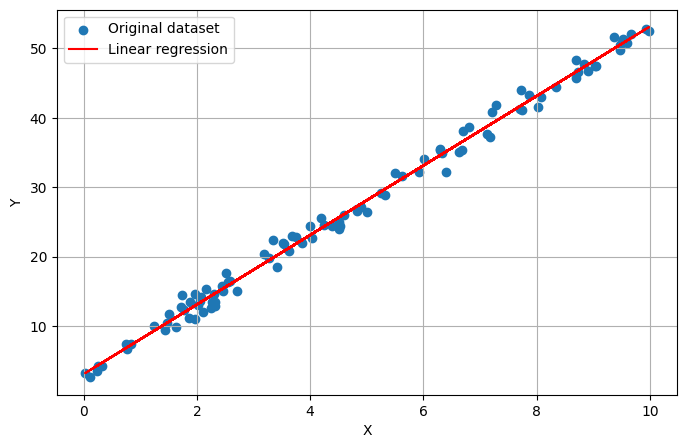

In [104]:
plt.figure(figsize=(8,5))
plt.scatter(X, y, label='Original dataset')
plt.plot(X, y_pred, color='red', label='Linear regression')
plt.xlabel('X')
plt.ylabel('Y')
plt.grid()
plt.legend()
plt.show()

Noise level: 0
Slope: 5.0000
Intercept: 3.0000
MSE: 0.0000
RMSE: 0.0000
R2: 1.0000

Noise level: 1
Slope: 4.9659
Intercept: 3.1394
MSE: 0.8399
RMSE: 0.9165
R2: 0.9959

Noise level: 2
Slope: 5.0520
Intercept: 2.7619
MSE: 5.5183
RMSE: 2.3491
R2: 0.9747

Noise level: 5
Slope: 5.0892
Intercept: 2.2654
MSE: 26.6709
RMSE: 5.1644
R2: 0.8901

Noise level: 10
Slope: 5.1069
Intercept: 3.5720
MSE: 102.7617
RMSE: 10.1371
R2: 0.6791



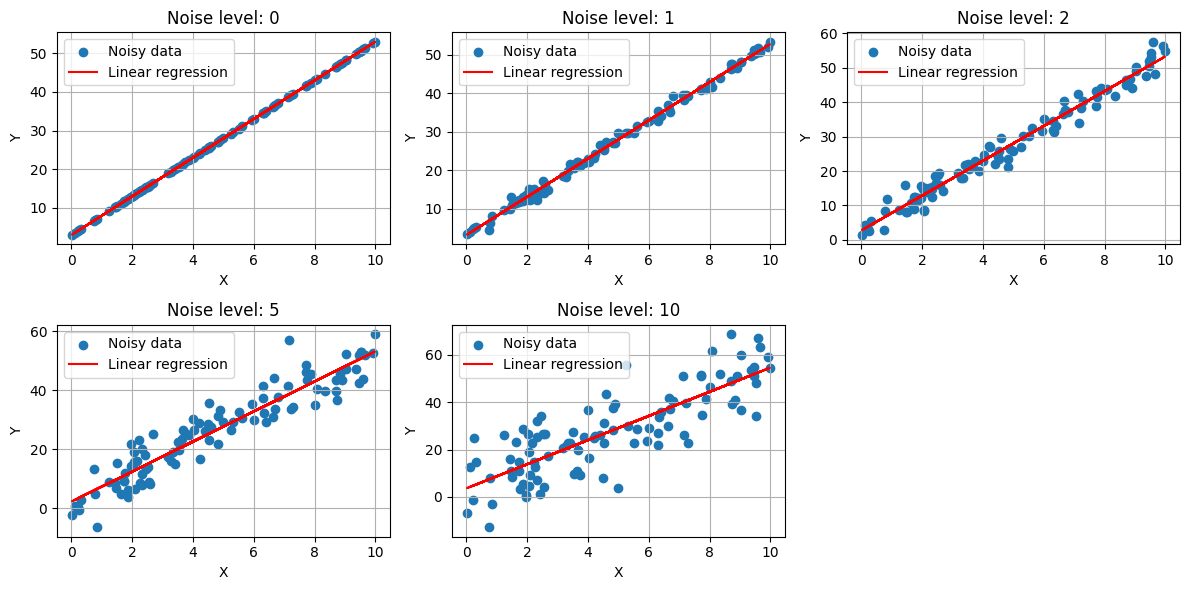

In [105]:
noise_levels = [0, 1, 2, 5, 10]
r2_scores=[]
plt.figure(figsize=(12, 6))
for i, noise in enumerate(noise_levels):
  y_noisy = 5 * X + 3 + np.random.normal(0, noise, 100)
  slope, intercept = linear_regression(X, y_noisy)
  y_pred = slope * X + intercept
  mse, rmse, r2 = evaluate_model(y_noisy, y_pred)
  print(f"Noise level: {noise:}")
  print(f"Slope: {slope:.4f}")
  print(f"Intercept: {intercept:.4f}")
  print(f"MSE: {mse:.4f}")
  print(f"RMSE: {rmse:.4f}")
  print(f"R2: {r2:.4f}")
  print("========================\n")
  r2_scores.append(r2)

  plt.subplot(2, 3, i+1)
  plt.title(f"Noise level: {noise}")
  plt.scatter(X, y_noisy, label="Noisy data")
  plt.plot(X, y_pred, color='red', label="Linear regression")
  plt.xlabel("X")
  plt.ylabel("Y")
  plt.grid()
  plt.legend()

plt.tight_layout()
plt.show()

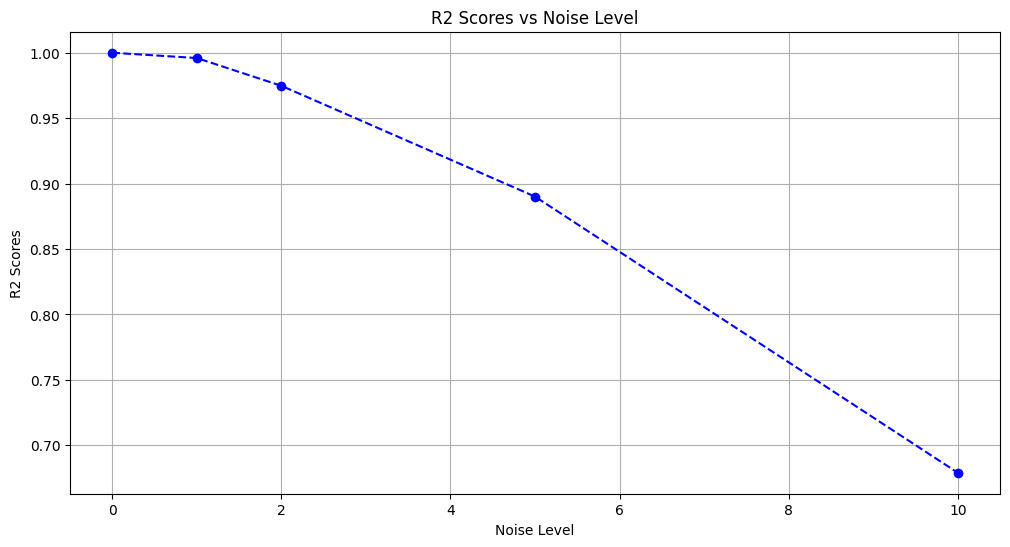

In [106]:
plt.figure(figsize=(12,6))
plt.plot(noise_levels, r2_scores, marker='o', linestyle='--', color='b')
plt.xlabel("Noise Level")
plt.ylabel("R2 Scores")
plt.title("R2 Scores vs Noise Level")
plt.grid()
plt.show()